# **Практикалық сабақ 3.** Matplotlib және Seaborn арқылы EDA орындау


**Мақсаты:** Matplotlib, Seborn кітапханаларының негізгі графиктерін құруды және оларды EDA кезінде қолдануды үйрену.
https://matplotlib.org/stable/users/explain/quick_start.html#quick-start

# ГЛОССАРИЙ


---




## EDA (Exploratory Data Analysis) — деректерді зерттеушілік талдау.

EDA — машиналық оқыту моделін құрмас бұрын деректерді жан-жақты зерттеу процесі.

EDA кезінде:

- деректердің көлемі мен бағандары қаралады;
- негізгі статистика есептеледі;
- бос мәндер мен дубликаттар анықталады;
- ауытқыма мәндер табылады;
- деректердің үлестірімі зерттеледі;
- айнымалылар арасындағы байланыс қаралады;
- нәтижелер графиктер арқылы көрсетіледі.

**Мысалы:**
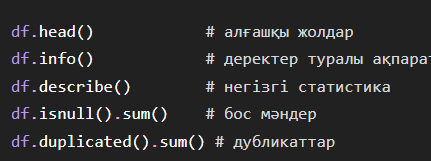

-------------------------------------------------------------------------------------

# API

**API (Application Programming Interface)** — бағдарламалар немесе кітапханалармен жұмыс істеуге арналған дайын командалар мен ережелер жиынтығы.

Мысалы, Seaborn кітапханасының API-іне мына функциялар кіреді:

```python
sns.scatterplot()  # нүктелік диаграмма
sns.histplot()     # гистограмма
sns.boxplot()      # қораптық диаграмма
sns.heatmap()      # жылу картасы
```

Яғни API — кітапхананың мүмкіндіктерін пайдалануға арналған **дайын құралдар жиынтығы**.

Қарапайым тілмен айтқанда, **API — бағдарламамен қалай байланысуға және оның функцияларын қалай қолдануға болатынын көрсететін интерфейс**.


---




# **1 Matplotlib**

☝ Matplotlib — Python тілінде графиктер мен диаграммалар құруға мүмкіндік беретін негізгі кітапханалардың бірі. Оның көмегімен сызықтық және нүктелік графиктерді, гистограммалар мен бағандық диаграммаларды құруға болады. Графиктер деректерді көрнекі түрде зерттеуге, салыстыруға және олардың арасындағы заңдылықтарды анықтауға көмектеседі.


**Matplotlib** сіздің деректеріңізді Figure ретінде бейнелейді. Олардың әрқайсысында бір немесе бірнеше Axes болуы мүмкін.

Axes — бұл нүктелер x-y координаттарымен белгіленетін аймақ.

Axes аймағы бар Figure құрудың ең қарапайым жолы — `pyplot.subplots' функциясын қолдану. Содан кейін **Axes** аймағында деректерді салу үшінAxes.plot  әдісін, ал фигураны экранда көрсету үшін 'show' функциясын пайдалана аламыз:

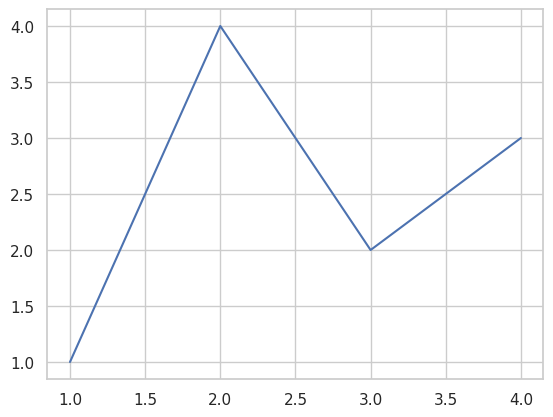

In [31]:
fig, ax = plt.subplots()             # Create a figure containing a single Axes.
ax.plot([1, 2, 3, 4], [1, 4, 2, 3])  # Plot some data on the Axes.
plt.show()

# Графикке берілетін деректер

Matplotlib график құру кезінде көбіне NumPy массивтерімен, сөздіктермен (dict) және Pandas DataFrame кестелерімен жұмыс істейді.

Қажет болған жағдайда деректерді NumPy массивіне түрлендіруге болады:

In [32]:
b = np.matrix([[1, 2], [3, 4]])
b_array = np.asarray(b)

DataFrame немесе сөздік қолданылған кезде баған атауларын көрсету жеткілікті:

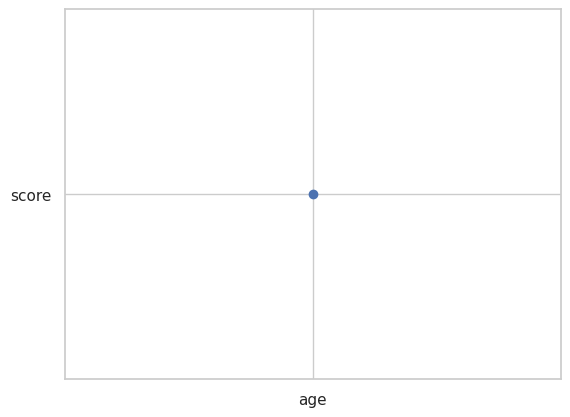

In [33]:
plt.scatter(
    x="age",
    y="score",
    data=df
)

# МЫСАЛ


---

Сөздік деректері арқылы нүктелік диаграмма құру

Мұнда:

- a — X осіндегі мәндер;
- b — Y осіндегі мәндер;
- c — нүктелердің түсін анықтайды;
- d — нүктелердің көлемін анықтайды;
- data=data — барлық мәндер data сөздігінен алынатынын көрсетеді.

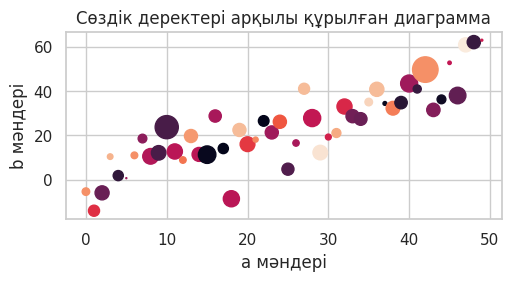

In [35]:
import numpy as np
import matplotlib.pyplot as plt

# Кездейсоқ мәндер өзгермеуі үшін
np.random.seed(42)

# Деректер сөздігін құру
data = {
    "a": np.arange(50),
    "c": np.random.randint(0, 50, 50),
    "d": np.random.randn(50)
}

# Жаңа деректерді қосу
data["b"] = data["a"] + 10 * np.random.randn(50)
data["d"] = np.abs(data["d"]) * 100

# Нүктелік диаграмма құру
fig, ax = plt.subplots(
    figsize=(5, 2.7),
    layout="constrained"
)

ax.scatter(
    "a",
    "b",
    c="c",
    s="d",
    data=data
)

# Ось атауларын жазу
ax.set_xlabel("a мәндері")
ax.set_ylabel("b мәндері")
ax.set_title("Сөздік деректері арқылы құрылған диаграмма")

plt.show()

# Matplotlib-те код жазу стильдері

Matplotlib-ті қолданудың екі негізгі тәсілі бар:

1) Объектіге бағытталған стиль (OO-style) — Figure және Axes объектілерін өзіміз құрып, графикті ax арқылы басқарамыз:



```
fig, ax = plt.subplots()
ax.plot(x, y)
ax.set_title("График")
```

2) Pyplot стилі — графикті plt функциялары арқылы тікелей құрамыз:



```
plt.plot(x, y)
plt.title("График")
```

- Қарапайым графиктер үшін pyplot стилі ыңғайлы.
- Ал бірнеше немесе күрделі графикпен жұмыс істегенде OO-style қолданған дұрыс.




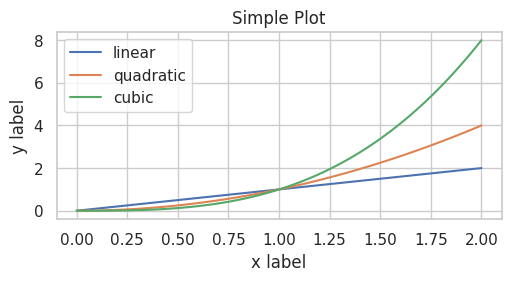

In [37]:
x = np.linspace(0, 2, 100)  # Sample data.

# Note that even in the OO-style, we use `.pyplot.figure` to create the Figure.
fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
ax.plot(x, x, label='linear')  # Plot some data on the Axes.
ax.plot(x, x**2, label='quadratic')  # Plot more data on the Axes...
ax.plot(x, x**3, label='cubic')  # ... and some more.
ax.set_xlabel('x label')  # Add an x-label to the Axes.
ax.set_ylabel('y label')  # Add a y-label to the Axes.
ax.set_title("Simple Plot")  # Add a title to the Axes.
ax.legend()  # Add a legend.

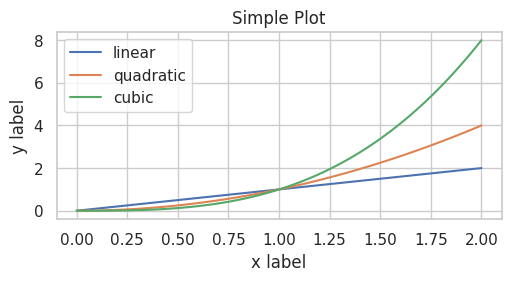

In [38]:
x = np.linspace(0, 2, 100)  # Sample data.

plt.figure(figsize=(5, 2.7), layout='constrained')
plt.plot(x, x, label='linear')  # Plot some data on the (implicit) Axes.
plt.plot(x, x**2, label='quadratic')  # etc.
plt.plot(x, x**3, label='cubic')
plt.xlabel('x label')
plt.ylabel('y label')
plt.title("Simple Plot")
plt.legend()

## 1. Кітапханаларды импорттау

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


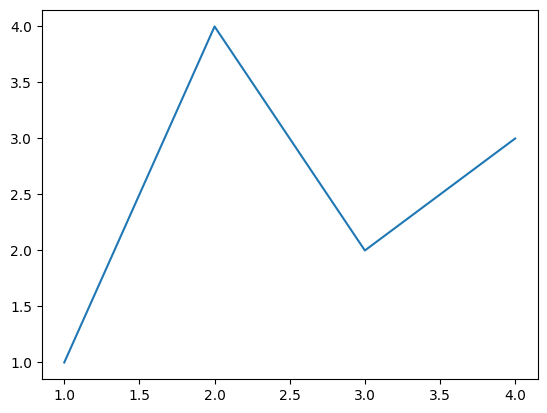

In [ ]:
fig, ax = plt.subplots()             #
ax.plot([1, 2, 3, 4], [1, 4, 2, 3])  # Plot some data on the Axes.
plt.show()                           # графикті көрсету, бұл қатарды жазбауға да болады.

<Figure size 640x480 with 0 Axes>

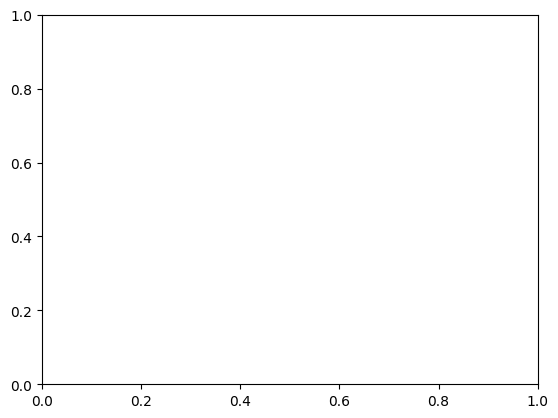

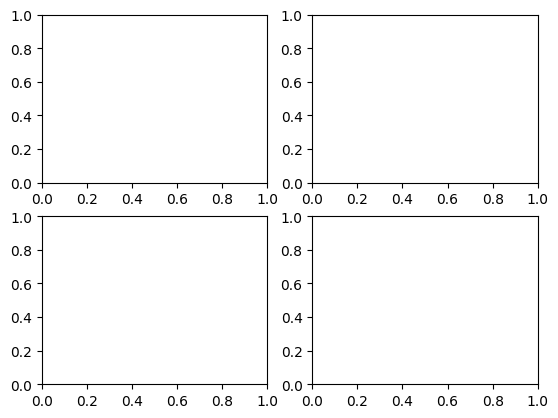

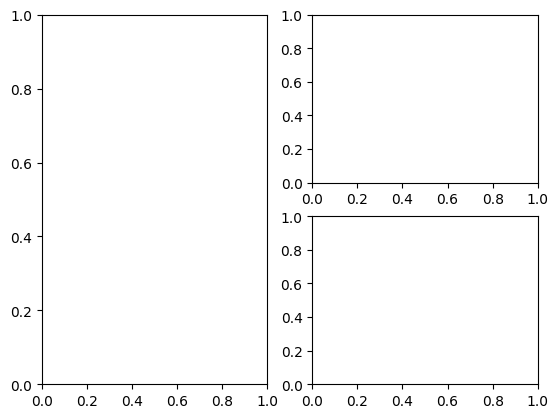

In [ ]:
fig = plt.figure()             # Axes жоқ бос сурет
fig, ax = plt.subplots()       # 1 Axes бар сурет
fig, axs = plt.subplots(2, 2)  # 2x2 grid Axes сурет
# сол жағында бір Axes, ал оң жағында екі Axes бар Figure:
fig, axs = plt.subplot_mosaic([['left', 'right_top'],
                               ['left', 'right_bottom']])

Axes (Координаталық жүйе аймағы)
Axes — бұл деректерді бейнелеуге арналған аймақты қамтитын және әдетте екі (немесе 3D жағдайында үш) Axis (ось) объектісін қамтитын Figure (сурет) элементіне бекітілген «Artist» (графикалық нысан).

Axes әдістері — график элементтерінің көпшілігін баптауға арналған негізгі интерфейс (деректерді қосу, ось шкалалары мен шекараларын басқару, белгілер қосу және т.б.).

Axis (Ось)
Бұл объектілер шкала мен шекараларды анықтайды, сондай-ақ бөлу сызықтарын (осьтегі белгілер) және олардың жазуларын (белгілерді сипаттайтын мәтін жолдары) қалыптастырады. Бөлу сызықтарының орналасуы Locator объектісі арқылы анықталады, ал жазулар Formatter арқылы пішімделеді. Дұрыс таңдалған Locator мен Formatter үйлесімі бөлу сызықтары мен жазулардың орналасуын өте дәл басқаруға мүмкіндік береді.



## 2. Қарапайым сызықтық график

Figure — бүкіл сурет, ал Axes — график салынатын аймақ. plot() нүктелерді сызықпен біріктіреді.



Төмендегі код `plot()` арқылы мәндерді сызықпен біріктіреді. Мұнда бір графикте үш функция салыстырылады: сызықтық \(y=x\), квадраттық \(y=x^2\) және кубтық \(y=x^3\). `xlabel()` және `ylabel()` осьтерге атау, `title()` графикке тақырып, ал `legend()` әр сызықтың түсіндірмесін қосады.


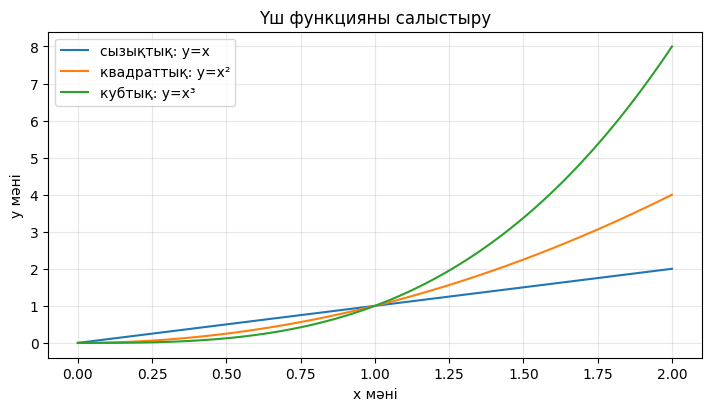

In [ ]:
x = np.linspace(0, 2, 100)

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.plot(x, x, label='сызықтық: y=x')
ax.plot(x, x**2, label='квадраттық: y=x²')
ax.plot(x, x**3, label='кубтық: y=x³')
ax.set_xlabel('x мәні')
ax.set_ylabel('y мәні')
ax.set_title('Үш функцияны салыстыру')
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()


**Талдау:** сызықтық функция бірқалыпты өседі. Квадраттық және кубтық функциялар x артқан сайын жылдамырақ өседі.

## 3. Нүктелік диаграмма — scatter()

scatter() екі сандық айнымалының байланысын зерттейді. plot() графигінен айырмашылығы — нүктелер сызықпен біріктірілмейді.

# scatter plot
Төмендегі код кездейсоқ деректер негізінде нүктелік диаграмма (scatter plot) құрады.
- a мәндері X осінде,
- b мәндері Y осінде көрсетіледі.
- Нүктелердің түсі c бағанына, ал көлемі d бағанына байланысты өзгереді.
- figsize график өлшемін белгілейді, ал соңғы екі команда X және Y осьтеріне атау береді.

Демек, Matplotlib **«data»** атаулы аргументін пайдалануға және x пен y айнымалыларына сәйкес келетін жолдарды беру арқылы графиктер құруға мүмкіндік береді.

Text(0, 0.5, 'entry b')

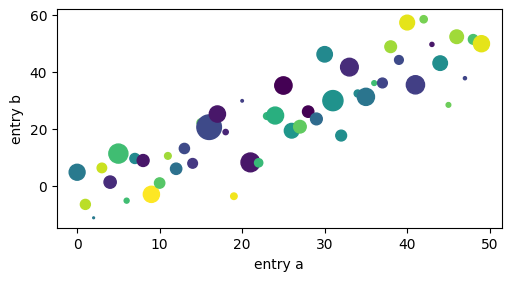

In [ ]:
np.random.seed(19680801)
data = {'a': np.arange(50),
        'c': np.random.randint(0, 50, 50),
        'd': np.random.randn(50)}
data['b'] = data['a'] + 10 * np.random.randn(50)
data['d'] = np.abs(data['d']) * 100

fig, ax = plt.subplots(figsize=(5, 2.7), layout='constrained')
ax.scatter('a', 'b', c='c', s='d', data=data)
ax.set_xlabel('entry a')
ax.set_ylabel('entry b')

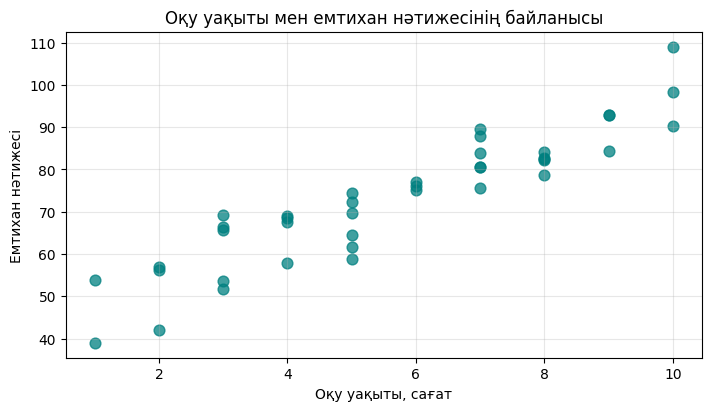

In [ ]:
np.random.seed(42)
study_hours = np.random.randint(1, 11, 40)
exam_score = 45 + study_hours * 5 + np.random.normal(0, 6, 40)

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.scatter(study_hours, exam_score, color='teal', s=60, alpha=0.75)
ax.set_xlabel('Оқу уақыты, сағат')
ax.set_ylabel('Емтихан нәтижесі')
ax.set_title('Оқу уақыты мен емтихан нәтижесінің байланысы')
ax.grid(True, alpha=0.3)
plt.show()


**Талдау:** нүктелер жоғары бағытталғандықтан, оқу уақыты артқан сайын емтихан нәтижесі де өсуге бейім.

## 4. Бағандық диаграмма — bar()

Бағандық диаграмма категориялардың мәндерін салыстыру үшін қолданылады.

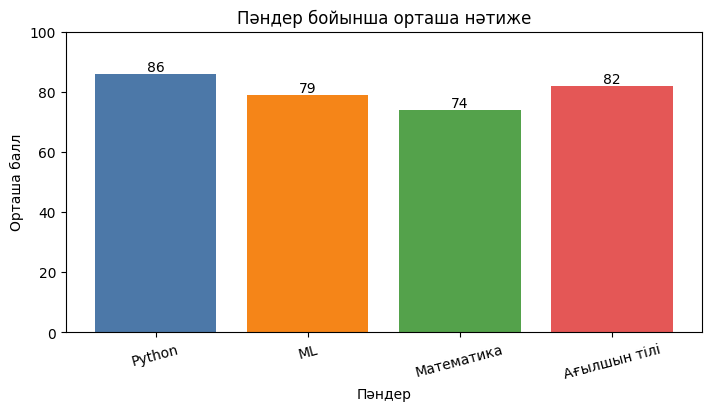

In [ ]:
subjects = ['Python', 'ML', 'Математика', 'Ағылшын тілі']
average_scores = [86, 79, 74, 82]

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
bars = ax.bar(subjects, average_scores, color=['#4C78A8', '#F58518', '#54A24B', '#E45756'])
ax.set_xlabel('Пәндер')
ax.set_ylabel('Орташа балл')
ax.set_title('Пәндер бойынша орташа нәтиже')
ax.set_ylim(0, 100)
ax.bar_label(bars)
plt.xticks(rotation=15)
plt.show()


## 5. Гистограмма — hist()

Гистограмма сандық айнымалы мәндерінің қалай таралғанын көрсетеді.

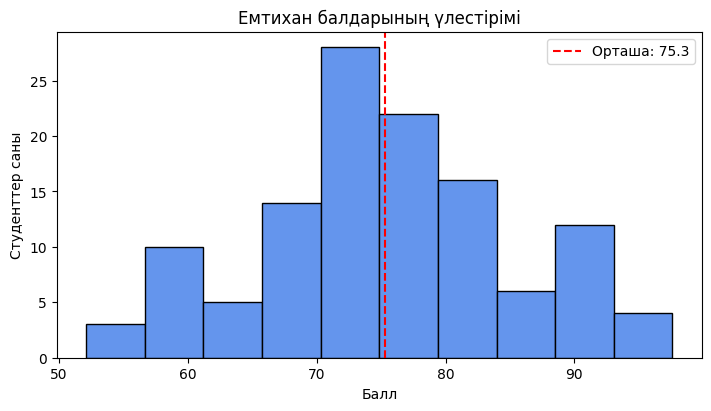

In [ ]:
np.random.seed(7)
scores = np.clip(np.random.normal(loc=75, scale=10, size=120), 0, 100)

fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
ax.hist(scores, bins=10, color='cornflowerblue', edgecolor='black')
ax.axvline(scores.mean(), color='red', linestyle='--', label=f'Орташа: {scores.mean():.1f}')
ax.set_xlabel('Балл')
ax.set_ylabel('Студенттер саны')
ax.set_title('Емтихан балдарының үлестірімі')
ax.legend()
plt.show()


## 6. Шағын EDA

Алдымен кестенің құрылымы мен статистикасын, кейін графиктерін зерттейміз.

In [ ]:
np.random.seed(10)
n = 80
df = pd.DataFrame({
    'study_hours': np.random.randint(1, 11, n),
    'attendance': np.random.randint(55, 101, n),
    'group': np.random.choice(['A', 'B', 'C'], n)
})
df['exam_score'] = np.clip(
    30 + 4 * df['study_hours'] + 0.25 * df['attendance'] + np.random.normal(0, 7, n),
    0, 100
)

display(df.tail())
print('Кесте өлшемі:', df.shape)
display(df.describe())


,study_hours,attendance,group,exam_score
75,6,94,C,66.768519
76,1,82,B,55.542725
77,3,94,B,67.705778
78,8,64,A,73.975576
79,4,62,A,58.978802


Кесте өлшемі: (80, 4)


,study_hours,attendance,exam_score
count,80.00000,80.0000,80.000000
mean,5.91250,79.1875,73.320319
std,3.13895,12.2165,14.507618
min,1.00000,55.0000,48.145631
25%,3.00000,70.7500,59.282568
50%,7.00000,80.0000,73.370400
75%,9.00000,88.0000,85.052278
max,10.00000,100.0000,100.000000


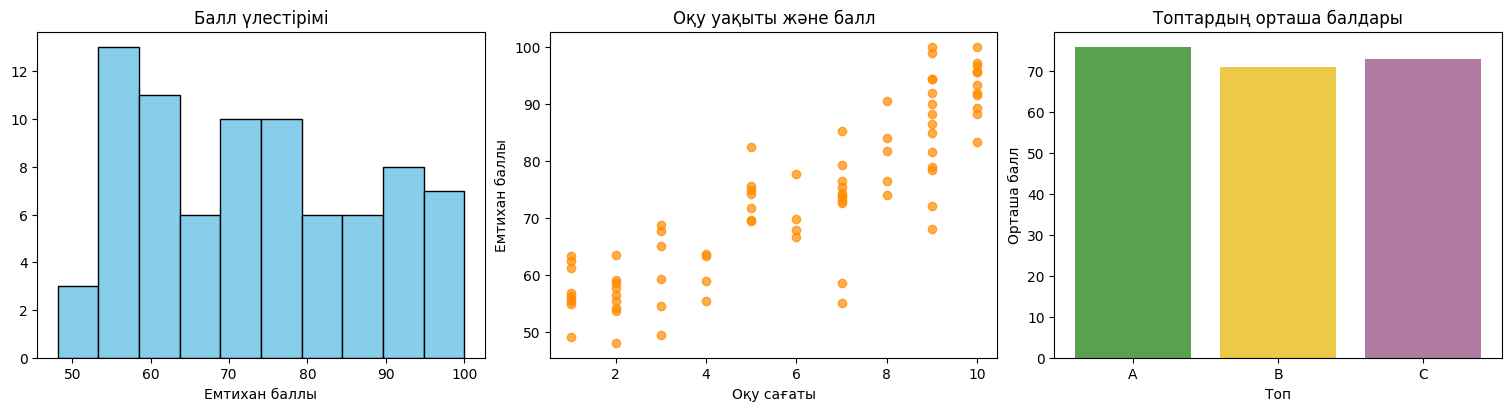

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')

axs[0].hist(df['exam_score'], bins=10, color='skyblue', edgecolor='black')
axs[0].set_title('Балл үлестірімі')
axs[0].set_xlabel('Емтихан баллы')

axs[1].scatter(df['study_hours'], df['exam_score'], alpha=0.7, color='darkorange')
axs[1].set_title('Оқу уақыты және балл')
axs[1].set_xlabel('Оқу сағаты')
axs[1].set_ylabel('Емтихан баллы')

group_means = df.groupby('group')['exam_score'].mean()
axs[2].bar(group_means.index, group_means.values, color=['#59A14F', '#EDC948', '#B07AA1'])
axs[2].set_title('Топтардың орташа балдары')
axs[2].set_xlabel('Топ')
axs[2].set_ylabel('Орташа балл')

plt.show()


## 7. Студенттің тапсырмасы

Жоғарыдағы df деректерін пайдаланып:

1. Сабаққа қатысу пайызының гистограммасын құрыңыз.
2. Қатысу пайызы мен емтихан баллының scatter plot-ын құрыңыз.
3. Әр топтағы студенттер санын бағандық диаграммамен көрсетіңіз.
4. Барлық графикке тақырып және ось атауларын қосыңыз.
5. Графиктер бойынша кемінде үш қорытынды жазыңыз.

In [ ]:
# 1-тапсырма: attendance бағанының гистограммасын құрыңыз

# Кодты осы жерге жазыңыз


In [ ]:
# 2-тапсырма: attendance және exam_score байланысын көрсетіңіз

# Кодты осы жерге жазыңыз


In [ ]:
# 3-тапсырма: әр топтағы студенттер санын көрсетіңіз

# Кодты осы жерге жазыңыз


## 8. Бақылау сұрақтары

1. Figure, Axes және Axis арасында қандай айырмашылық бар?
2. plot() пен scatter() қай кезде қолданылады?
3. Гистограмма қандай ақпарат береді?
4. legend() және grid() функциялары не үшін қажет?
5. EDA кезінде графиктер бойынша қандай қорытынды жасауға болады?

## **2 Seaborn**

https://seaborn.pydata.org/tutorial/introduction.html


Seaborn — Python тілінде статистикалық деректерді график арқылы зерттеуге және түсінуге арналған Python кітапханасы. Ол matplotlib негізінде құрылған және pandas деректер құрылымдарымен тығыз үйлеседі.

Seaborn — DataFrame мен массивтердегі мәліметтерді пайдаланып, түсінікті әрі көрнекі графиктерді оңай құруға мүмкіндік береді.


Міне, Seaborn-ның мүмкіндіктерін көрсететін мысал:

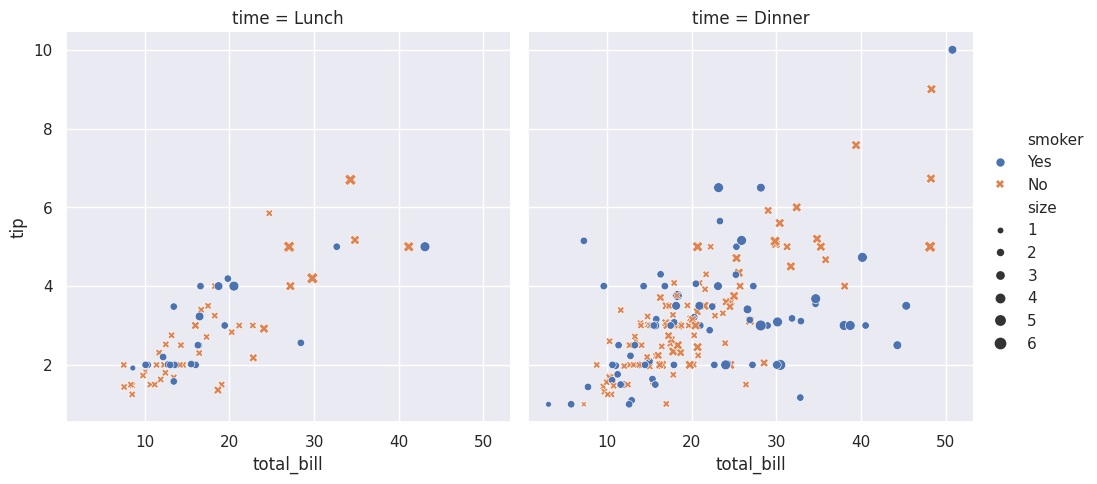

In [ ]:
# Import seaborn
import seaborn as sns

# Apply the default theme
sns.set_theme()

# Load an example dataset
tips = sns.load_dataset("tips")

# Create a visualization
sns.relplot(
    data=tips,
    x="total_bill", y="tip", col="time",
    hue="smoker", style="smoker", size="size",
)

## 1. Кітапханаларды импорттау

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Статистикалық графиктер құру

Деректерді көрсетуге арналған жалғыз әмбебап график жоқ. График түрі зерттелетін сұраққа байланысты таңдалады.

Seaborn-дағы ***relplot()*** функциясы айнымалылар арасындағы байланысты көрсетеді:

- екі сандық айнымалы үшін нүктелік диаграмма қолданылады;

- уақыт бойынша өзгерісті көрсету үшін сызықтық график қолайлы.

График түрін kind параметрі арқылы таңдауға болады:

In [ ]:
sns.relplot(data=df, x="x", y="y", kind="scatter")

#немесе

sns.relplot(data=df, x="time", y="value", kind="line")

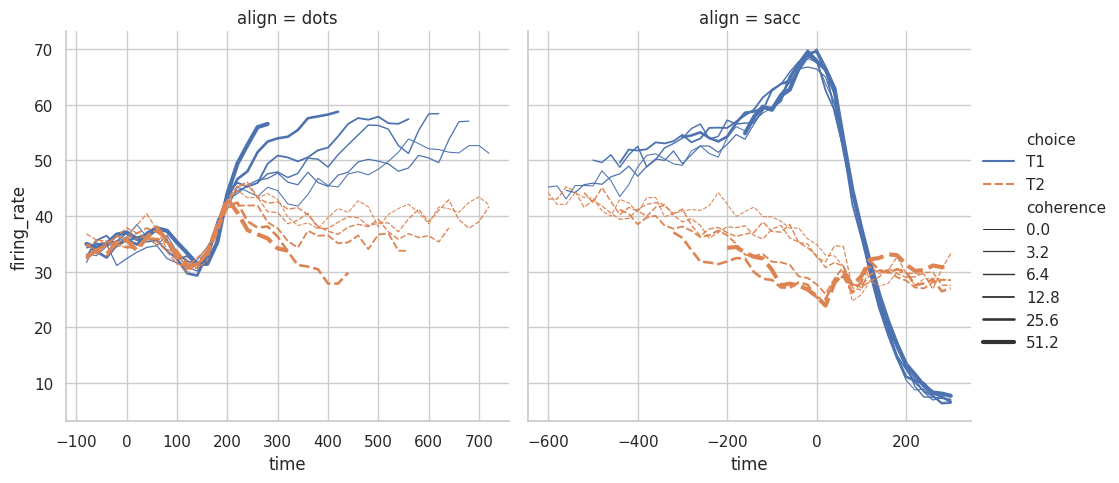

In [ ]:
dots = sns.load_dataset("dots")
sns.relplot(
    data=dots, kind="line",
    x="time", y="firing_rate", col="align",
    hue="choice", size="coherence", style="choice",
    facet_kws=dict(sharex=False),
)

# 3. Статистикалық бағалау

Көбінесе бізді басқа айнымалыларға тәуелді функция ретіндегі бір айнымалының орташа мәні қызықтырады.

Seaborn кітапханасының көптеген функциялары осы сұрақтарға жауап беру үшін қажетті статистикалық бағалауды автоматты түрде орындайды:

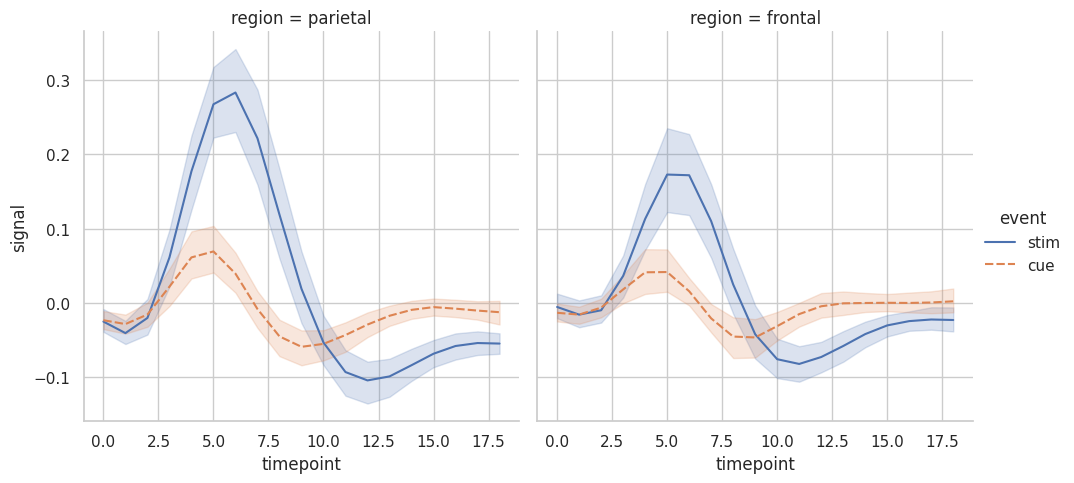

In [ ]:
fmri = sns.load_dataset("fmri")
sns.relplot(
    data=fmri, kind="line",
    x="timepoint", y="signal", col="region",
    hue="event", style="event",
)

#4. Тарату көріністері

Статистикалық талдау деректер жиынындағы айнымалылардың таралуы туралы білімді қажет етеді.

Seaborn функциясы displot() таралуларды визуализациялаудың бірнеше тәсілдерін қолдайды. Оларға гистограммалар сияқты классикалық әдістер және ядро ​​тығыздығын бағалау сияқты есептеуді қажет ететін тәсілдер жатады:

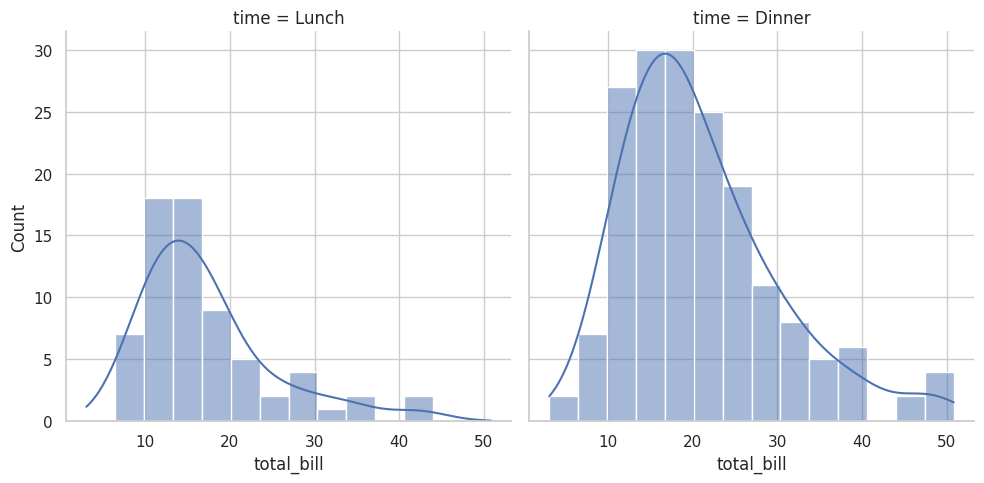

In [ ]:
sns.displot(data=tips, x="total_bill", col="time", kde=True)

# 5. Категориялық деректерге арналған

Seaborn кітапханасындағы бірқатар арнайы график түрлері категориялық деректерді визуализациялауға бағытталған.

Оларға `catplot()` функциясы арқылы қол жеткізуге болады.

Бұл графиктер деректерді егжей-тегжейлі көрсетудің әртүрлі деңгейлерін ұсынады. Mысалы, «swarm» (шоғыр) графигін салу арқылы әрбір бақылауды көруге болады; бұл — нүктелер бір-бірімен қабаттасып қалмас үшін олардың категориялық ось бойындағы орналасуын реттейтін шашырау диаграммасы (scatter plot):


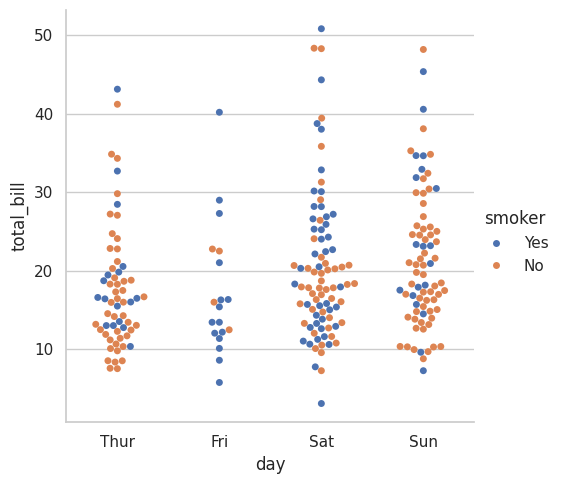

In [ ]:
sns.catplot(data=tips, kind="swarm", x="day", y="total_bill", hue="smoker")

# 6. Күрделі деректер жиынындағы көп айнымалы көріністер

Кейбір seaborn функциялары деректер жиынының ақпараттық қорытындыларын тез беру үшін бірнеше график түрлерін біріктіреді.

1) Біріншісі, jointplot(), бір қатынасқа бағытталған. Ол екі айнымалы арасындағы бірлескен үлестірімді әр айнымалының шекті үлестірімімен бірге көрсетеді:

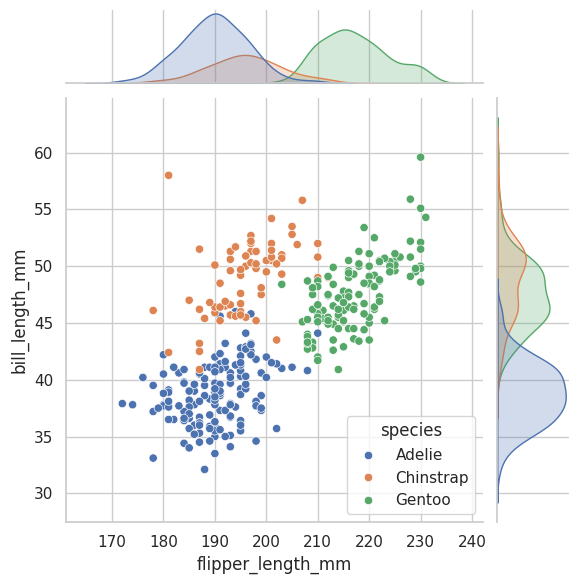

In [ ]:
penguins = sns.load_dataset("penguins")
sns.jointplot(data=penguins, x="flipper_length_mm", y="bill_length_mm", hue="species")

2) Eкіншісі — pairplot() — кеңірек көрініс ұсынады: ол барлық жұптық байланыстар мен әрбір айнымалы үшін сәйкесінше бірлескен және шеткі үлестірімдерді көрсетеді.

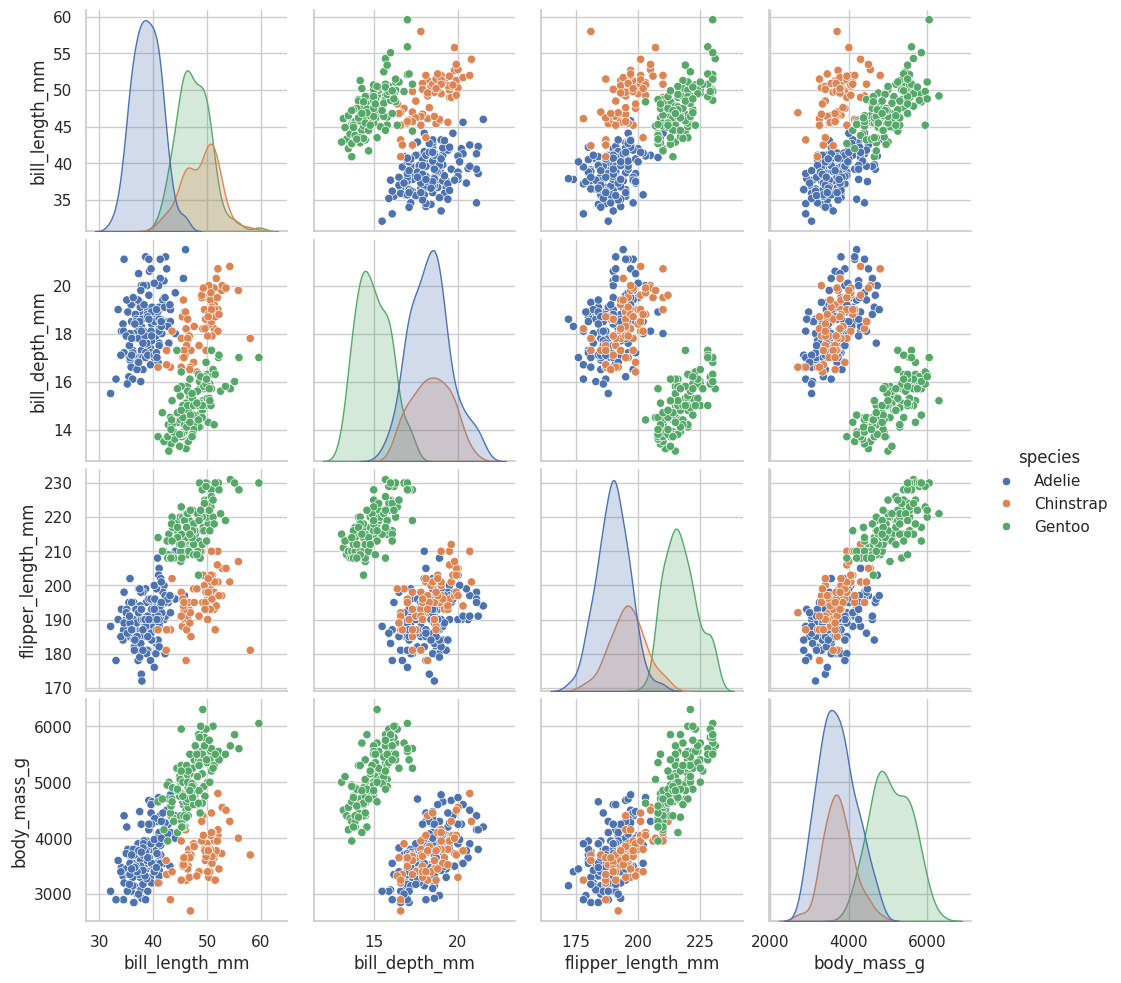

In [ ]:
sns.pairplot(data=penguins, hue="species")

# Seaborn мен Matplotlib байланысы

Seaborn — Matplotlib негізінде жұмыс істейтін кітапхана.

Seaborn арқылы түсінікті әрі әдемі статистикалық графиктерді жылдам құруға болады. Ал Matplotlib графиктің тақырыбын, осьтерін, түсін, өлшемін және басқа элементтерін толық өзгертуге мүмкіндік береді.

**Қысқаша айтқанда:**

Seaborn — графикті оңай әрі жылдам құрады;
Matplotlib — графикті толық безендіреді және реттейді.

Көбіне екі кітапхана бірге қолданылады:

## Matplotlib пен Seaborn айырмашылығы

- Matplotlib графиктің әр бөлігін толық басқаруға мүмкіндік береді.
- Seaborn статистикалық графиктерді DataFrame негізінде жылдам және көркем құрады.
- Seaborn графиктері де Matplotlib Figure және Axes объектілерінде салынады.

# **ЖАТТЫҒУ**

**1) Кітапханаларды орнату**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Seaborn графиктеріне дайын дизайн қолданамыз:

In [ ]:
sns.set_theme(style="whitegrid")

**2) Деректерді жүктеу**

tіps деректер жиынтығында мейрамхана клиенттерінің төлемі, шайпұлы, жынысы, темекі шегуі, келген күні және адам саны туралы ақпарат бар.

In [ ]:
tips = sns.load_dataset("tips")

tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


Деректер туралы жалпы ақпарат:

In [ ]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


Негізгі статистика:

In [ ]:
tips.describe()

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


**3. Сандық айнымалылардың байланысы**

scatterplot() екі сандық айнымалы арасындағы байланысты көрсетеді.

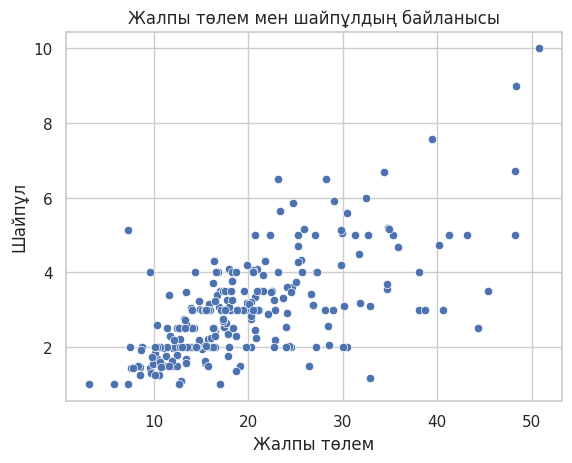

In [ ]:
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip"
)

plt.title("Жалпы төлем мен шайпұлдың байланысы")
plt.xlabel("Жалпы төлем")
plt.ylabel("Шайпұл")
plt.show()

Қорытынды: жалпы төлем көбейген сайын шайпұл да өсуге бейім.

**4) Категорияны түс арқылы көрсету**

hue параметрі нүктелерді категория бойынша әртүрлі түспен көрсетеді.

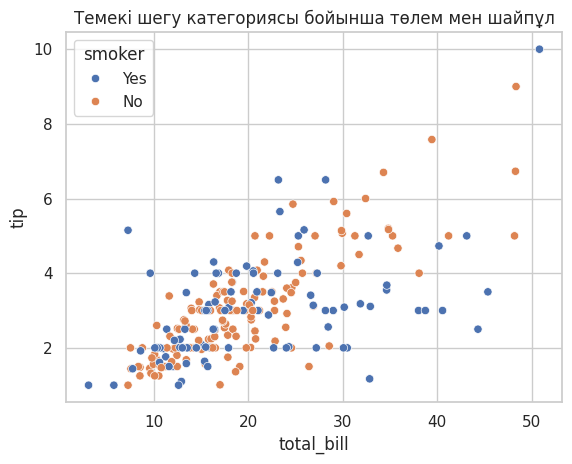

In [ ]:
sns.scatterplot(
    data=tips,
    x="total_bill",
    y="tip",
    hue="smoker"
)

plt.title("Темекі шегу категориясы бойынша төлем мен шайпұл")
plt.show()

**5) Деректердің үлестірімі**

histplot() сандық мәндердің қалай таралғанын көрсетеді.

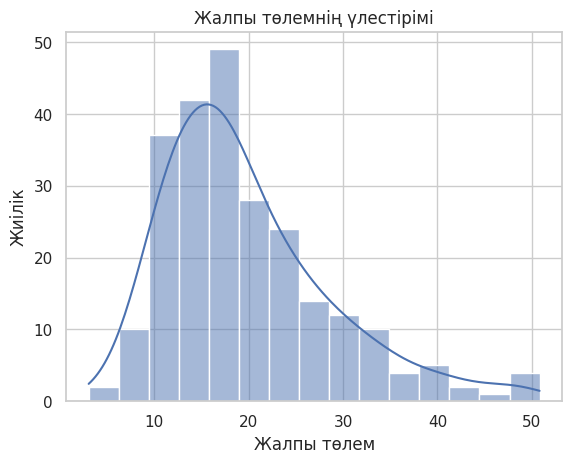

In [ ]:
sns.histplot(
    data=tips,
    x="total_bill",
    bins=15,
    kde=True
)

plt.title("Жалпы төлемнің үлестірімі")
plt.xlabel("Жалпы төлем")
plt.ylabel("Жиілік")
plt.show()

**6) Категориялардың санын салыстыру**

countplot() әр категорияда қанша жазба бар екенін көрсетеді.

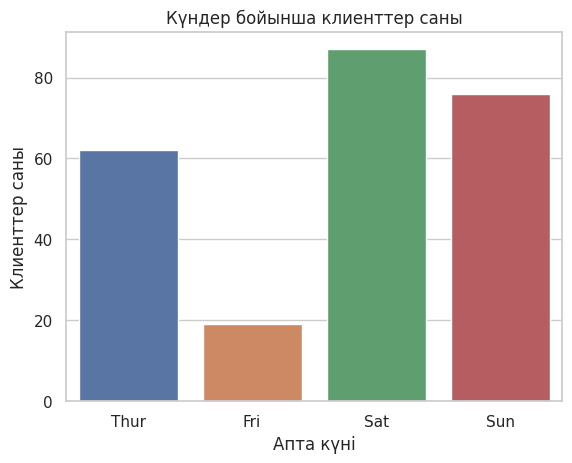

In [ ]:
sns.countplot(
    data=tips,
    x="day",
    hue="day",
    legend=False
)

plt.title("Күндер бойынша клиенттер саны")
plt.xlabel("Апта күні")
plt.ylabel("Клиенттер саны")
plt.show()

**7) Топтар бойынша мәндерді салыстыру**

boxplot() деректердің таралуын, медианасын және ауытқыма мәндерін көрсетеді.

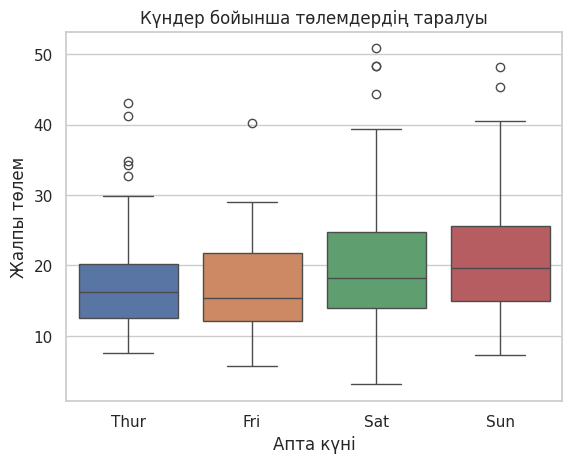

In [ ]:
sns.boxplot(
    data=tips,
    x="day",
    y="total_bill",
    hue="day",
    legend=False
)

plt.title("Күндер бойынша төлемдердің таралуы")
plt.xlabel("Апта күні")
plt.ylabel("Жалпы төлем")
plt.show()

## EDA

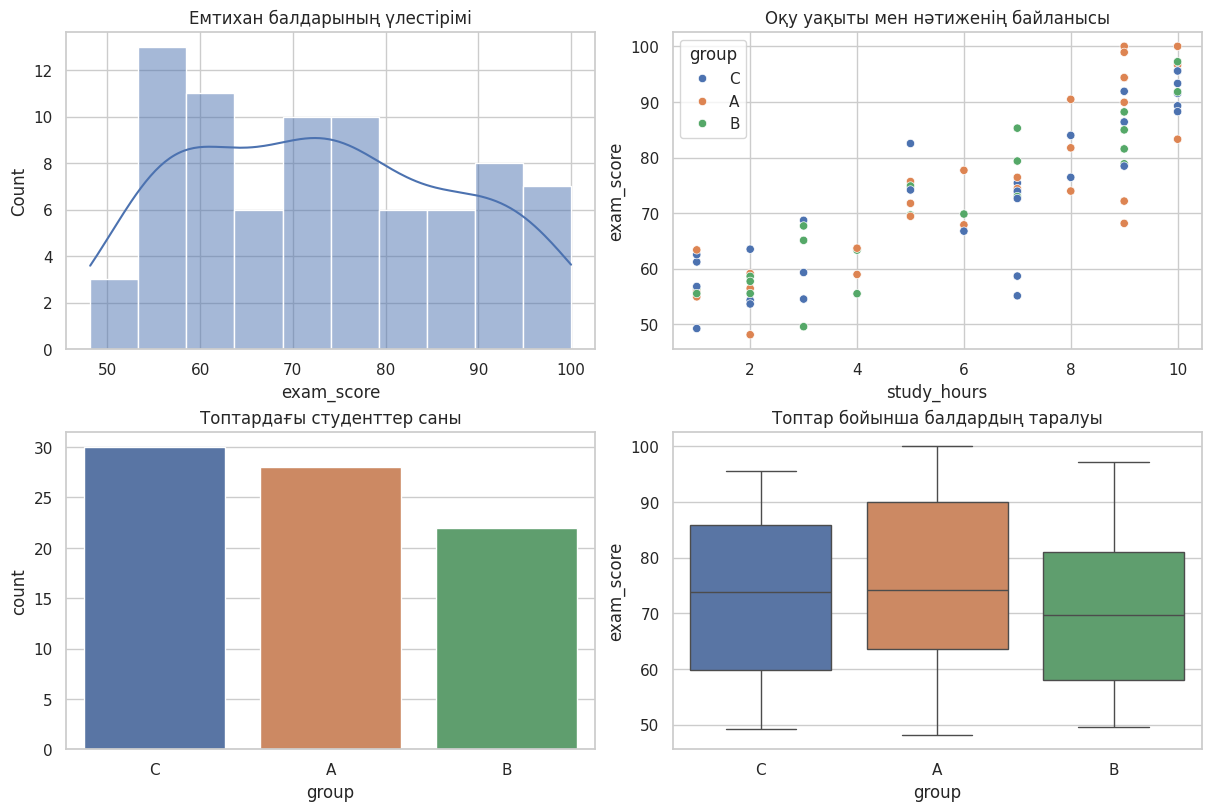

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')

sns.histplot(data=df, x='exam_score', bins=10, kde=True, ax=axs[0, 0])
axs[0, 0].set_title('Емтихан балдарының үлестірімі')

sns.scatterplot(data=df, x='study_hours', y='exam_score', hue='group', ax=axs[0, 1])
axs[0, 1].set_title('Оқу уақыты мен нәтиженің байланысы')

sns.countplot(data=df, x='group', hue='group', legend=False, ax=axs[1, 0])
axs[1, 0].set_title('Топтардағы студенттер саны')

sns.boxplot(data=df, x='group', y='exam_score', hue='group', legend=False, ax=axs[1, 1])
axs[1, 1].set_title('Топтар бойынша балдардың таралуы')

plt.show()

## ТАПСЫРМАЛАР

**tіps деректерін пайдаланып:**

1) tip бағанының гистограммасын құрыңыз.
2) total_bill және tip байланысын көрсететін scatter plot жасаңыз.
3) Нүктелерді time бағаны бойынша түспен ажыратыңыз.
4) Күндер бойынша шайпұл мөлшерін boxplot арқылы салыстырыңыз.
5) Әр графикке тақырып және ось атауларын қосыңыз.


In [ ]:
# 1-тапсырма: tip бағанының гистограммасын құрыңыз.

# Кодты осы жерге жазыңыз

In [ ]:
# 2-тапсырма: total_bill және tip байланысын көрсететін scatter plot жасаңыз.

# Кодты осы жерге жазыңыз

In [ ]:
# 3-тапсырма: Нүктелерді time бағаны бойынша түспен ажыратыңыз.

# Кодты осы жерге жазыңыз

In [ ]:
# 4-тапсырма: Күндер бойынша шайпұл мөлшерін boxplot арқылы салыстырыңыз.

# Кодты осы жерге жазыңыз

## Қорытынды

- ***Matplotlib*** - графиктері деректердің үлестірімін, категориялар арасындағы айырмашылықты және сандық айнымалылардың байланысын көруге мүмкіндік береді.

- ***Seaborn*** — Python тілінде статистикалық графиктерді құруға арналған кітапхана. Ол matplotlib негізінде құрылған және pandas деректер құрылымдарымен тығыз үйлеседі.

